# Fairness Check: โมเดลปฏิบัติต่อแต่ละกลุ่มเท่าเทียมไหม (Yanisa, wk6–7)

ตรวจตาม README หัวข้อ 6.4 และทำต่อจากตัวเลขตั้งต้นใน DS-04 ของ [review Data Engineering](../docs/review_data_engineering_S.md) ด้วย **Fairlearn** `MetricFrame`

**คำถาม:** ถ้า HR ใช้ระบบนี้หาคนที่จะลาออก มีกลุ่มไหนที่ระบบ "มองไม่เห็น" มากกว่ากลุ่มอื่นไหม

**กลุ่มที่ตรวจ (protected attribute):** เพศ, ช่วงอายุ, สถานภาพสมรส

### ตัวชี้วัด (ภาษาคน) ใช้เกณฑ์เตือนที่คะแนน 0.5 ตามที่ทีมตัดสินใจ
| ตัวชี้วัด | ความหมาย |
| :--- | :--- |
| ลาออกจริง (base rate) | ในกลุ่มนี้ลาออกจริงกี่ % |
| ถูกเตือน (selection rate) | ระบบเตือนว่าเสี่ยงกี่ % ของกลุ่ม |
| **จับได้ (TPR, recall)** | ในคนที่ลาออกจริง ระบบเตือนได้กี่ % ← **เกณฑ์หลัก** |
| เตือนผิด (FPR) | ในคนที่ไม่ได้ลาออก ระบบเตือนผิดกี่ % |
| AUC | ความแม่นในการเรียงลำดับความเสี่ยงภายในกลุ่ม |

### ทำไมใช้ "จับได้" (equal opportunity) เป็นเกณฑ์หลัก ไม่ใช่ "ถูกเตือนเท่ากัน" (demographic parity)
คนอายุน้อยและคนโสดลาออกจริงมากกว่า (จาก EDA) ถ้าบังคับให้ทุกกลุ่มถูกเตือนเท่ากัน ระบบต้องเตือนผิดกลุ่มหนึ่งหรือมองข้ามคนเสี่ยงจริงอีกกลุ่ม เกณฑ์ที่เหมาะกับงานนี้คือ **"คนที่จะลาออกจริง ไม่ว่าอยู่กลุ่มไหน ควรถูกเตือนในสัดส่วนใกล้กัน"** เพราะการถูกเตือน = ได้รับการดูแลจาก HR

---
## ขั้นตอนที่ 1: คะแนนแบบ out-of-fold

ถ้าวัดบนข้อมูลที่โมเดลเคยเห็นตอนเทรน ผลจะดีเกินจริง จึงแบ่งข้อมูล 5 ส่วน เทรน 4 ส่วนแล้วให้คะแนนส่วนที่เหลือ วนจนครบ ทุกคน 1,470 คนจึงได้คะแนนจากโมเดลที่ไม่เคยเห็นตัวเขา (มากกว่าชุดสอบ 294 คน ทำให้แต่ละกลุ่มมีคนพอวิเคราะห์)

ใช้ฟีเจอร์และ hyperparameter เดียวกับโมเดลจริง `attrition-xgboost-P` v1 (`PARAMS` ใน [`src/train.py`](../src/train.py))

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from fairlearn.metrics import MetricFrame
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

sys.path.append(os.path.abspath(".."))
from src.business_rules import HIGH_RISK, MEDIUM_RISK
from src.clean_pipeline import RAW_FILENAME, TARGET_COLUMN, clean_data, load_raw_data
from src.feature_pipeline import SELECTED_FEATURES, add_features

RAW_PATH = os.path.join("..", "data", "raw", RAW_FILENAME)
FIG_DIR = os.path.join("..", "docs", "figures", "fairness_Y")
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

# ค่าเดียวกับ PARAMS ใน src/train.py (ผล Optuna ของ Puripat) ถ้าแก้ที่นั่นให้แก้ที่นี่ด้วย
PARAMS = {"n_estimators": 500, "max_depth": 2, "learning_rate": 0.03132429398213804, "subsample": 0.664952951683747,
          "colsample_bytree": 0.5305253930212119, "min_child_weight": 10, "reg_lambda": 1.2338780559789992}
THRESHOLD = 0.5  # เกณฑ์เตือนที่ทีมตัดสินใจ (docs/report_business_logic_draft_S.md)
BOOT_N, BOOT_SEED = 10_000, 42  # bootstrap มาตรฐานของโปรเจกต์ (เหมือน src/train.py)


def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")


raw = load_raw_data(RAW_PATH)
data = add_features(clean_data(raw), only=SELECTED_FEATURES)
X, y = data.drop(columns=TARGET_COLUMN), data[TARGET_COLUMN].to_numpy()
print(X.shape, f"ลาออก {y.mean():.1%}")

(1470, 50) ลาออก 16.1%


In [2]:
def oof_scores(X, y, seed=42):
    """คะแนน out-of-fold 5-fold และโมเดลของแต่ละ fold (ใช้ต่อในขั้นทดลองสลับเพศ)"""
    scores = np.zeros(len(y))
    folds = []
    for train_idx, test_idx in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        ytr = y[train_idx]
        spw = (ytr == 0).sum() / (ytr == 1).sum()  # คิดจากส่วนที่ใช้เทรนเท่านั้น
        model = XGBClassifier(**PARAMS, scale_pos_weight=spw, random_state=42, n_jobs=4)
        model.fit(X.iloc[train_idx], ytr)
        scores[test_idx] = model.predict_proba(X.iloc[test_idx])[:, 1]
        folds.append((model, test_idx))
    return scores, folds


scores, folds = oof_scores(X, y)
print(f"OOF AUC ทั้งหมด: {roc_auc_score(y, scores):.3f}")

OOF AUC ทั้งหมด: 0.829


---
## ขั้นตอนที่ 2: ตารางรายกลุ่มด้วย Fairlearn MetricFrame

In [3]:
groups = pd.DataFrame({
    "อายุ": pd.cut(raw["Age"], [18, 30, 40, 50, 61], right=False, labels=["18-29", "30-39", "40-49", "50+"]).astype(str),
    "สถานภาพ": raw["MaritalStatus"].map({"Single": "โสด", "Married": "แต่งงาน", "Divorced": "หย่าร้าง"}),
    "เพศ": raw["Gender"].map({"Female": "หญิง", "Male": "ชาย"}),
})


def tpr(y_true, s):
    return ((s >= THRESHOLD) & (y_true == 1)).sum() / (y_true == 1).sum()


def fpr(y_true, s):
    return ((s >= THRESHOLD) & (y_true == 0)).sum() / (y_true == 0).sum()


METRICS = {
    "คน": lambda y_true, s: len(y_true),
    "ลาออกจริง": lambda y_true, s: y_true.mean(),
    "ถูกเตือน": lambda y_true, s: (s >= THRESHOLD).mean(),
    "จับได้ (TPR)": tpr,
    "เตือนผิด (FPR)": fpr,
    "AUC": roc_auc_score,
}
PCT = {"ลาออกจริง": "{:.1%}", "ถูกเตือน": "{:.1%}", "จับได้ (TPR)": "{:.1%}", "เตือนผิด (FPR)": "{:.1%}", "AUC": "{:.2f}"}


def frames(scores):
    return {col: MetricFrame(metrics=METRICS, y_true=y, y_pred=scores, sensitive_features=groups[col])
            for col in groups}


mfs = frames(scores)
table = pd.concat({col: mf.by_group for col, mf in mfs.items()}, names=["มิติ", "กลุ่ม"])
table["คน"] = table["คน"].astype(int)
table.style.format(PCT)

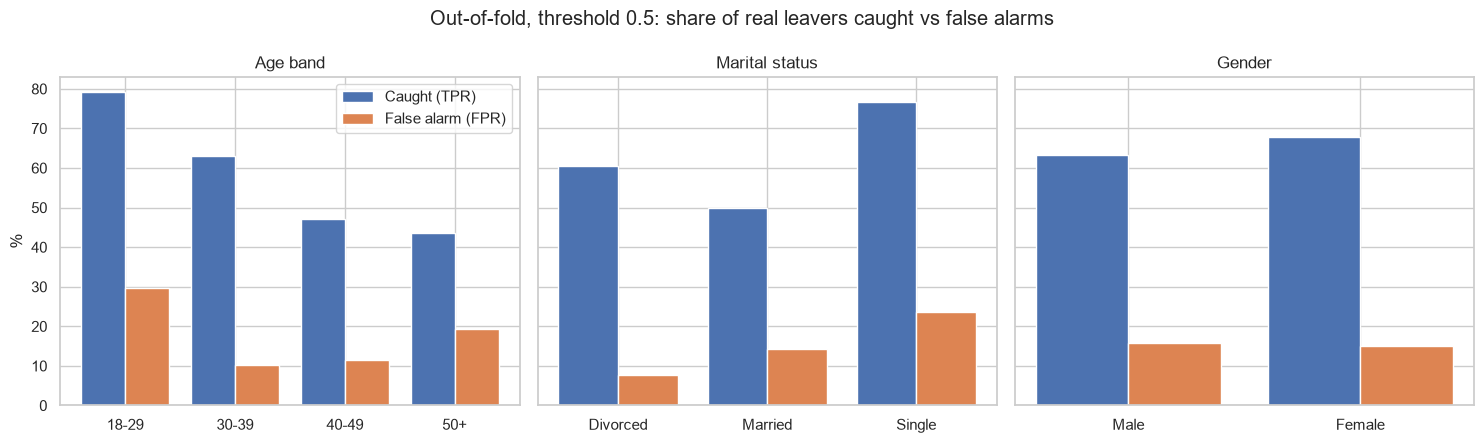

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (col, mf) in zip(axes, mfs.items()):
    bg = mf.by_group
    x = np.arange(len(bg))
    ax.bar(x - 0.2, bg["จับได้ (TPR)"] * 100, width=0.4, label="Caught (TPR)", color="#4C72B0")
    ax.bar(x + 0.2, bg["เตือนผิด (FPR)"] * 100, width=0.4, label="False alarm (FPR)", color="#DD8452")
    labels = {"หญิง": "Female", "ชาย": "Male", "โสด": "Single", "แต่งงาน": "Married", "หย่าร้าง": "Divorced"}
    ax.set_xticks(x, [labels.get(g, g) for g in bg.index])
    ax.set_title({"อายุ": "Age band", "สถานภาพ": "Marital status", "เพศ": "Gender"}[col])
axes[0].set_ylabel("%")
axes[0].legend()
fig.suptitle(f"Out-of-fold, threshold {THRESHOLD}: share of real leavers caught vs false alarms")
fig.tight_layout()
save(fig, "01_tpr_fpr_by_group")
plt.show()

---
## ขั้นตอนที่ 3: ช่องว่างระหว่างกลุ่ม + ช่วงความเชื่อมั่น

- **ช่องว่าง (difference)** = กลุ่มที่ดีที่สุด − กลุ่มที่แย่ที่สุด ยิ่งใกล้ 0 ยิ่งเท่าเทียม
- **อัตราส่วน (ratio)** = กลุ่มที่แย่ที่สุด ÷ กลุ่มที่ดีที่สุด ยิ่งใกล้ 1 ยิ่งเท่าเทียม

ช่องว่าง TPR ที่วัดได้อาจเกิดจากความบังเอิญได้ เพราะบางกลุ่มมีคนลาออกจริงไม่กี่สิบคน จึงหาช่วงความเชื่อมั่น 95% ด้วย bootstrap (สุ่มคนซ้ำแบบใส่คืน 10,000 รอบ) ถ้า**ช่วงไม่คร่อม 0** แปลว่าต่างกันจริง

In [5]:
def tpr_gap_ci(scores, col, n=BOOT_N, seed=BOOT_SEED):
    rng = np.random.default_rng(seed)
    g = groups[col].to_numpy()
    levels = np.unique(g)
    caught = (scores >= THRESHOLD) & (y == 1)
    gaps = np.empty(n)
    for b in range(n):
        i = rng.integers(0, len(y), len(y))
        rates = [caught[i][g[i] == lv].sum() / max((y[i][g[i] == lv] == 1).sum(), 1) for lv in levels]
        gaps[b] = max(rates) - min(rates)
    return np.percentile(gaps, [2.5, 97.5])


gap_rows = []
for col, mf in mfs.items():
    lo, hi = tpr_gap_ci(scores, col)
    gap_rows.append({
        "มิติ": col,
        "ช่องว่าง TPR": mf.difference()["จับได้ (TPR)"],
        "TPR 95% CI": f"{lo:.2f}–{hi:.2f}",
        "อัตราส่วน TPR": mf.ratio()["จับได้ (TPR)"],
        "ช่องว่าง ถูกเตือน (demographic parity)": mf.difference()["ถูกเตือน"],
        "ช่องว่าง ลาออกจริง": mf.difference()["ลาออกจริง"],
    })
gaps = pd.DataFrame(gap_rows).set_index("มิติ")
gaps.style.format({"ช่องว่าง TPR": "{:.2f}", "อัตราส่วน TPR": "{:.2f}",
                   "ช่องว่าง ถูกเตือน (demographic parity)": "{:.2f}", "ช่องว่าง ลาออกจริง": "{:.2f}"})

,ช่องว่าง TPR,TPR 95% CI,อัตราส่วน TPR,ช่องว่าง ถูกเตือน (demographic parity),ช่องว่าง ลาออกจริง
มิติ,,,,,
อายุ,0.36,0.22–0.58,0.55,0.29,0.18
สถานภาพ,0.27,0.15–0.40,0.65,0.24,0.15
เพศ,0.04,0.00–0.17,0.93,0.01,0.02


---
## ขั้นตอนที่ 4: ทดลองสลับเพศ (counterfactual)

เอาพนักงานคนเดิม เปลี่ยนแค่เพศ (หญิง ↔ ชาย) ค่าอื่นเหมือนเดิมทุกอย่าง แล้วให้โมเดลของ fold เดิมคิดคะแนนใหม่ ถ้าโมเดลไม่ใช้เพศ คะแนนต้องไม่เปลี่ยนเลย ระดับความเสี่ยงตาม README 6.1: สูง ≥ 0.7, ปานกลาง ≥ 0.4

In [6]:
def band(s):
    return np.select([s >= HIGH_RISK, s >= MEDIUM_RISK], ["High", "Medium"], "Low")


flipped = np.zeros(len(y))
for model, test_idx in folds:
    Xf = X.iloc[test_idx].copy()
    Xf["Gender"] = 1 - Xf["Gender"]
    flipped[test_idx] = model.predict_proba(Xf)[:, 1]

delta = np.abs(flipped - scores)
changed = (band(flipped) != band(scores)).sum()
print(f"ระดับความเสี่ยงเปลี่ยน: {changed} จาก {len(y):,} คน ({changed / len(y):.1%})")
print(f"คะแนนเปลี่ยนเฉลี่ย {delta.mean():.3f}, สูงสุด {delta.max():.3f}")

ระดับความเสี่ยงเปลี่ยน: 89 จาก 1,470 คน (6.1%)
คะแนนเปลี่ยนเฉลี่ย 0.023, สูงสุด 0.111


---
## ขั้นตอนที่ 5: ทดลองตัด protected attribute ออกจากโมเดล

ข้อเสนอข้อ 2 ใน DS-04: ถ้าไม่ให้โมเดลเห็นเพศและสถานภาพสมรส ความแม่นลดไหม และช่องว่างระหว่างกลุ่มดีขึ้นไหม (**เป็นการทดลองเท่านั้น** การเปลี่ยนโมเดลจริงต้องตัดสินใจร่วมกับ Puripat + Saphondanai)

ไม่ทดลองตัดอายุ เพราะอายุเป็นปัจจัยสำคัญอันดับต้นๆ (EDA และ Survival) และช่องว่างของกลุ่มอายุมาจากการที่คนอายุมากลาออกน้อยและลาออกด้วยเหตุผลที่ข้อมูลไม่มี ไม่ได้มาจากการที่โมเดลเห็นอายุโดยตรง

In [7]:
marital_cols = [c for c in X.columns if c.startswith("MaritalStatus_")]
variants = {
    "โมเดลปัจจุบัน": X,
    "ตัดเพศ": X.drop(columns=["Gender"]),
    "ตัดเพศ + สถานภาพ": X.drop(columns=["Gender", *marital_cols]),
}

compare = []
for name, Xv in variants.items():
    s = scores if name == "โมเดลปัจจุบัน" else oof_scores(Xv, y)[0]
    row = {"แบบ": name, "AUC รวม": roc_auc_score(y, s), "จับได้รวม": tpr(y, s)}
    for col, mf in frames(s).items():
        row[f"ช่องว่าง TPR {col}"] = mf.difference()["จับได้ (TPR)"]
    compare.append(row)
pd.DataFrame(compare).set_index("แบบ").style.format("{:.3f}")

,AUC รวม,จับได้รวม,ช่องว่าง TPR อายุ,ช่องว่าง TPR สถานภาพ,ช่องว่าง TPR เพศ
แบบ,,,,,
โมเดลปัจจุบัน,0.829,0.650,0.356,0.267,0.045
ตัดเพศ,0.827,0.646,0.431,0.267,0.106
ตัดเพศ + สถานภาพ,0.829,0.654,0.449,0.218,0.093


---
## ขั้นตอนที่ 6: สรุปผล

คะแนน out-of-fold ทั้ง 1,470 คน (AUC รวม 0.83) เกณฑ์เตือน 0.5 ตัวเลขใกล้เคียงกับ DS-04 ที่ทีมวัดไว้ก่อนหน้า ต่างกันเล็กน้อยเพราะการสุ่มแบ่ง fold

**1. อายุ: ไม่เท่าเทียมชัดเจน** (ช่องว่าง TPR 0.36, CI 0.22–0.58 ไม่คร่อม 0)
- คนอายุ 18–29 ที่จะลาออก ระบบจับได้ **79%** แต่คนอายุ 40–49 จับได้ **47%** และ 50+ จับได้ **44%**
- พูดง่ายๆ: คนอายุ 40 ขึ้นไปที่กำลังจะลาออก **ระบบมองไม่เห็นเกินครึ่ง**
- ความแม่นภายในกลุ่มก็ลดลงตามอายุ (AUC 0.84 → 0.71) กลุ่ม 50+ มีคนลาออกจริงแค่ 23 คน ตัวเลขจึงแกว่งได้มาก

**2. สถานภาพสมรส: ไม่เท่าเทียม** (ช่องว่าง TPR 0.27, CI 0.15–0.40)
- โสดจับได้ 77% แต่งงานจับได้ 50%
- ส่วนหนึ่งมาจากข้อมูลจำลอง: คนโสดทุกคนใน IBM ไม่มี stock option ซึ่งเป็นปัจจัยเสี่ยงสำคัญ (ดู [Survival Analysis](08_survival_analysis_Y.ipynb) ข้อ 4)

**3. เพศ: ภาพรวมเท่าเทียม** (ช่องว่าง TPR 0.04, CI 0.00–0.17) แต่**โมเดลใช้เพศโดยตรง**
- ทดลองสลับเพศคนเดิม ระดับความเสี่ยงเปลี่ยน **89 จาก 1,470 คน (6.1%)** คะแนนเปลี่ยนสูงสุด 0.11
- คนสองคนที่ต่างกันแค่เพศอาจได้ระดับความเสี่ยงต่างกัน เป็นประเด็นจริยธรรมและ PDPA แม้ตัวเลขรวมจะดูเท่ากัน

**4. ตัดเพศและสถานภาพออกจากโมเดล: ความแม่นไม่ลด แต่ช่องว่างไม่หาย**
- AUC รวมเท่าเดิม (0.827–0.829) และจับคนลาออกได้รวมเท่าเดิม (~65%)
- ช่องว่างของอายุและเพศไม่ได้ดีขึ้น (เปลี่ยนในช่วงที่แกว่งตามการสุ่ม) ช่องว่างของสถานภาพลดลงเล็กน้อย 0.27 → 0.22
- แปลว่าความไม่เท่าเทียมมาจาก**ข้อมูล** (กลุ่มอายุมากลาออกน้อยและลาออกด้วยเหตุผลที่ข้อมูลไม่มี) มากกว่าการที่โมเดลเห็นคอลัมน์เหล่านี้
- **ข้อเสนอต่อเจ้าของโมเดล (Puripat + Saphondanai):** พิจารณาตัด `Gender` ออก เพราะไม่เสียความแม่นและแก้ปัญหาข้อ 3 ได้ตรงๆ

### เกณฑ์ที่ยอมรับได้ (ข้อเสนอให้ทีมตัดสินใจ ตาม README 6.4)
เสนอให้ใช้ **อัตราส่วน TPR (กลุ่มแย่สุด ÷ กลุ่มดีสุด) ≥ 0.8** คล้ายกฎ four-fifths ที่ใช้ทั่วไปในงานตรวจความเป็นธรรม
| มิติ | อัตราส่วน TPR | ผ่านเกณฑ์ 0.8 |
| :--- | ---: | :--- |
| เพศ | 0.93 | ผ่าน |
| สถานภาพ | 0.65 | ไม่ผ่าน |
| อายุ | 0.55 | ไม่ผ่าน |

### ข้อความเตือนสำหรับรายงานและหน้าเว็บ (ร่าง ผูกกับ UX-06)
> ระบบจับพนักงานอายุ 40 ปีขึ้นไปและพนักงานที่แต่งงานแล้วที่กำลังจะลาออกได้น้อยกว่ากลุ่มอื่น (ประมาณครึ่งหนึ่ง) การที่พนักงานไม่อยู่ในกลุ่มเสี่ยงสูงไม่ได้แปลว่าไม่ต้องดูแล ควรใช้ร่วมกับการพูดคุยของหัวหน้างาน

### ข้อจำกัด
- IBM dataset เป็นข้อมูลจำลอง ผลกับบริษัทจริงต้องตรวจซ้ำหลัง recalibrate (README 6.5)
- คะแนนจากการแบ่ง fold แบบเดียว (seed 42) ถ้าเปลี่ยน seed ตัวเลขรายกลุ่มจะขยับได้หลายจุด % โดยเฉพาะกลุ่มเล็ก
- ยังไม่ได้ลองวิธีปรับเกณฑ์แยกกลุ่ม (เช่น Fairlearn `ThresholdOptimizer`) เพราะต้องใช้อายุหรือสถานภาพตอนตัดสิน ซึ่งเป็นการปฏิบัติต่างกันตาม protected attribute โดยตรง ควรปรึกษาทีมก่อน